In [3]:
from data_engineering.adsb.read_adsb import read_adsb
from datetime import date, datetime
import polars as pl
from data_engineering.bts.read_bts_ontime_to_flights import get_bts_flights_for_day
from flights.flights_match_adsb import flights_match_adsb
target_date = date(2026, 4, 1)
df_adsb = read_adsb(target_date, source="adsbx")
df_flights = get_bts_flights_for_day(target_date)

10 overlapping flights found for 2026-04-01


In [15]:
df_flights.filter(pl.col("icao") == "a0681c")

icao,callsign,registration,takeoff_time,takeoff_airport_ident,landing_time,landing_airport_ident,first_message_time,first_lat,first_lon,first_baro_altitude_ft,first_geom_altitude_ft,last_message_time,last_lat,last_lon,last_baro_altitude_ft,last_geom_altitude_ft,pia,ladd,military,interesting,aircraft_type,owner,aircraft_description,category
str,str,str,datetime[ms],str,datetime[ms],str,datetime[ms],f64,f64,i64,i64,datetime[ms],f64,f64,i64,i64,bool,bool,bool,bool,str,str,str,str
"""a0681c""",null,"""N125UW""",2026-04-01 00:22:00,"""KPHX""",2026-04-01 02:07:00,"""KSFO""",null,null,null,null,null,null,null,null,null,null,false,false,false,false,null,null,null,"""A3"""
"""a0681c""",null,"""N125UW""",2026-04-01 16:42:00,"""KSFO""",2026-04-01 18:10:00,"""KPHX""",null,null,null,null,null,null,null,null,null,null,false,false,false,false,null,null,null,"""A3"""
"""a0681c""",null,"""N125UW""",2026-04-01 19:47:00,"""KPHX""",2026-04-01 21:28:00,"""KSAT""",null,null,null,null,null,null,null,null,null,null,false,false,false,false,null,null,null,"""A3"""
"""a0681c""",null,"""N125UW""",2026-04-01 22:41:00,"""KSAT""",2026-04-01 23:27:00,"""KDFW""",null,null,null,null,null,null,null,null,null,null,false,false,false,false,null,null,null,"""A3"""


In [5]:
from flights.flights_match_adsb import get_matching_icaos_in_flights
df = get_matching_icaos_in_flights(df_flights, df_adsb, datetime(target_date.year, target_date.month, target_date.day))

In [6]:
df.filter(pl.col("icao") == "a0205c")

icao,callsign,registration,takeoff_time,takeoff_airport_ident,landing_time,landing_airport_ident,first_message_time,first_lat,first_lon,first_baro_altitude_ft,first_geom_altitude_ft,last_message_time,last_lat,last_lon,last_baro_altitude_ft,last_geom_altitude_ft,pia,ladd,military,interesting,aircraft_type,owner,aircraft_description,category
str,str,str,datetime[ms],str,datetime[ms],str,datetime[ms],f64,f64,i64,i64,datetime[ms],f64,f64,i64,i64,bool,bool,bool,bool,str,str,str,str


In [ ]:
icao = "a0205c"
df_fights = df_flights.filter(pl.col("icao") == icao)
df_adsb = df_adsb.filter(pl.col("icao") == icao)
flights_match_adsb(df_flights,df_adsb,datetime(target_date.year, target_date.month, target_date.day))

In [7]:
df_2 = pl.read_parquet('/Volumes/T2-SSD/planequery/data/experiments/comparison-mike/0fb63f25-7663-45e5-a7b1-aa22c1ecc4d0_flights_evaluation_matches.parquet')

In [13]:
COLUMNS = ["icao", "takeoff_time", "landing_time", "takeoff_airport_ident", "landing_airport_ident", "takeoff_time_df1", "landing_time_df1", "takeoff_airport_ident_df1", "landing_airport_ident_df1", "match_status"] 
df_2 = df_2.select(COLUMNS)
df_2 = df_2.filter((pl.col("icao") == "a0205c") & (pl.col("takeoff_time").dt.date() == date(2026,4,1)))
df_2

icao,takeoff_time,landing_time,takeoff_airport_ident,landing_airport_ident,takeoff_time_df1,landing_time_df1,takeoff_airport_ident_df1,landing_airport_ident_df1,match_status
str,datetime[ms],datetime[ms],str,str,datetime[ms],datetime[ms],str,str,str
"""a0205c""",2026-04-01 00:16:16.520,2026-04-01 01:40:11.480,"""KORD""","""KMEM""",2026-04-01 00:16:00,2026-04-01 01:40:00,"""KORD""","""KMEM""","""both"""
"""a0205c""",2026-04-01 02:57:36.260,2026-04-01 04:12:58.170,"""KMEM""","""KIAH""",2026-04-01 02:57:00,2026-04-01 04:13:00,"""KMEM""","""KIAH""","""both"""
"""a0205c""",2026-04-01 12:18:39.020,2026-04-01 14:15:06.671,"""KIAH""","""MMOX""",null,null,null,null,"""df0_only"""
"""a0205c""",2026-04-01 15:44:10.895,2026-04-01 17:53:10.540,"""MMOX""","""KIAH""",null,null,null,null,"""df0_only"""
"""a0205c""",2026-04-01 20:11:49.990,2026-04-01 22:21:37.090,"""KIAH""","""KCLT""",2026-04-01 20:11:00,2026-04-01 22:20:00,"""KIAH""","""KCLT""","""both"""


## BTS flights per day in April 2026

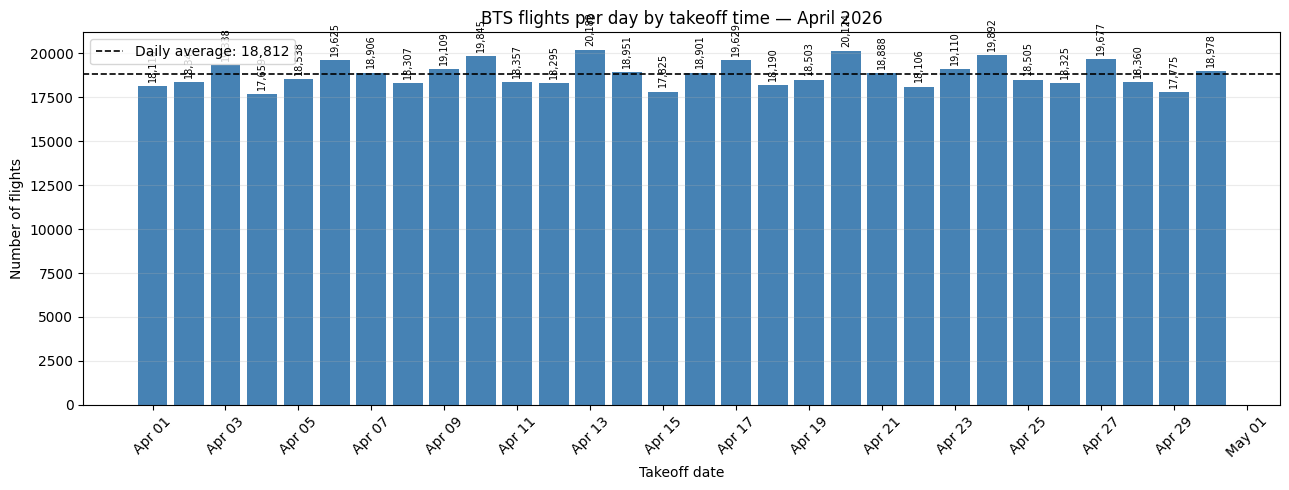

takeoff_date,number_of_flights
date,u32
2026-04-01,18110
2026-04-02,18347
2026-04-03,19338
2026-04-04,17659
2026-04-05,18538
…,…
2026-04-26,18325
2026-04-27,19677
2026-04-28,18360


In [14]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import polars as pl

BTS_APRIL_PATH = "/Volumes/T2-SSD/planequery/data/flights/bts/v3/year=2026/month=04/bts_flights.parquet"

bts_flights_per_day = (
    pl.scan_parquet(BTS_APRIL_PATH)
    .filter(
        (pl.col("takeoff_time").dt.year() == 2026)
        & (pl.col("takeoff_time").dt.month() == 4)
    )
    .group_by(pl.col("takeoff_time").dt.date().alias("takeoff_date"))
    .agg(pl.len().alias("number_of_flights"))
    .sort("takeoff_date")
    .collect()
)

dates = bts_flights_per_day.get_column("takeoff_date").to_list()
counts = bts_flights_per_day.get_column("number_of_flights").to_list()
daily_average = sum(counts) / len(counts)

fig, ax = plt.subplots(figsize=(13, 5))
bars = ax.bar(dates, counts, width=0.82, color="steelblue")
ax.axhline(
    daily_average,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label=f"Daily average: {daily_average:,.0f}",
)
ax.set_title("BTS flights per day by takeoff time — April 2026")
ax.set_xlabel("Takeoff date")
ax.set_ylabel("Number of flights")
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
ax.legend()

for bar, count in zip(bars, counts):
    ax.annotate(
        f"{count:,}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        va="bottom",
        rotation=90,
        fontsize=7,
    )

fig.tight_layout()
plt.show()

bts_flights_per_day